In [1]:

# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Student_Depression_Dataset.csv")

df_original = df.copy()

In [3]:
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [4]:
df.isna().sum()

# No NAs here

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [5]:
df.duplicated().sum()

# No duplicates

np.int64(0)

In [6]:
# Checking value_counts for the columns

for column in df.columns:
    values = df[column].value_counts()
    print(values)
    print()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

Age
23    1161
21     726
22     614
25     523
20     513
24     430
26     187
18      86
27      83
19      65
28      62
17      14
Name: count, dtype: int64

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

Current_semester
5     752
4     553
2     543
8     511
3     511
6     500
7     404
9     286
11    119
10    114
1      88
0      42
12     40
13      1
Name: count, dtype: int64

CGPA
3.00    280
3.60    142
3.50    135
4.00    130
3.89    130
       ... 
2.29      1
2.43      1
2.47      1
2.48      1
2.42      1
Name: count, Length: 169, dtype

We can see how the target variable is pretty inbalanced, but so are many of the other ones. Like marital_status, family_background, friend_circle.

## Cleaning the columns

In [7]:

varlist =  ['friend_circle', 'Depression']

# Defining the map function
def binary_map(x):
    return x.map({'Yes': 1, "No": 0})

# Applying the function
df[varlist] = df[varlist].apply(binary_map)

df["Gender"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

df['Living_style'] = df["Living_style"].map({
    "Bachelor": 0,
    "Family": 1
})

df["Family_background"] = df["Family_background"].map({
    "Lower Middle class": 0,
    "Middle class": 1,
    "Rich class": 2
})

df["Health_condition"] = df["Health_condition"].map({
    "Critical": 3,
    "Abnormal": 2,
    "Normal": 1,
    "Good": 0
})

In [8]:
# Get dummies for the nominal categories
df = pd.get_dummies(
    df,
    columns=["Home_division", "Marital_status", "Relationship_status"],
    drop_first=True,
    dtype=int
)

In [9]:
df

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
0,1,22,1,0,8,3.43,1,3,10113,1,...,0,0,0,0,0,0,0,1,0,1
1,0,19,1,0,2,3.70,1,2,13815,1,...,0,0,0,0,0,0,0,1,0,1
2,0,23,1,1,8,3.28,0,2,15450,1,...,1,0,0,0,0,0,0,1,0,1
3,0,20,1,1,2,3.77,0,0,17413,0,...,1,0,0,0,0,0,0,1,0,0
4,1,21,1,1,1,4.00,0,2,16693,1,...,1,0,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,1,26,1,1,11,2.97,0,3,12619,1,...,0,1,0,0,0,0,1,0,1,0
4460,0,28,0,1,8,2.60,0,1,2806,1,...,0,0,0,1,0,0,0,1,0,1
4461,1,23,1,0,10,2.80,0,0,14066,0,...,0,0,0,1,0,0,0,0,1,0
4462,1,23,1,1,5,3.00,1,1,14338,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
df.head(10)

# Quick sanity check that everything is OK. Looks to be ML-ready. :)

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
0,1,22,1,0,8,3.43,1,3,10113,1,...,0,0,0,0,0,0,0,1,0,1
1,0,19,1,0,2,3.70,1,2,13815,1,...,0,0,0,0,0,0,0,1,0,1
2,0,23,1,1,8,3.28,0,2,15450,1,...,1,0,0,0,0,0,0,1,0,1
3,0,20,1,1,2,3.77,0,0,17413,0,...,1,0,0,0,0,0,0,1,0,0
4,1,21,1,1,1,4.00,0,2,16693,1,...,1,0,0,0,0,0,0,1,0,1
5,1,24,1,0,9,3.80,1,1,17244,0,...,0,0,0,0,0,0,0,1,0,1
6,1,21,0,1,9,3.50,1,1,1648,0,...,1,0,0,0,0,0,0,1,0,1
7,1,19,1,1,2,2.71,1,2,16782,1,...,0,0,0,1,0,0,0,1,0,1
8,1,21,1,1,3,3.10,1,2,13386,1,...,1,0,0,0,0,0,0,1,0,1
9,1,22,1,1,4,3.34,1,1,18131,0,...,0,0,1,0,0,0,0,0,1,0


In [11]:
df.dtypes
# All good

Gender                                     int64
Age                                        int64
Family_background                          int64
Living_style                               int64
Current_semester                           int64
CGPA                                     float64
friend_circle                              int64
Health_condition                           int64
Cost_without_study                         int64
Depression                                 int64
Home_division_Chittagong                   int64
Home_division_Dhaka                        int64
Home_division_Khulna                       int64
Home_division_Mymensingh                   int64
Home_division_Rajshahi                     int64
Home_division_Rangpur                      int64
Home_division_Sylhet                       int64
Marital_status_Separated                   int64
Marital_status_Unmarried                   int64
Relationship_status_In a Relationship      int64
Relationship_status_

## Quick EDA

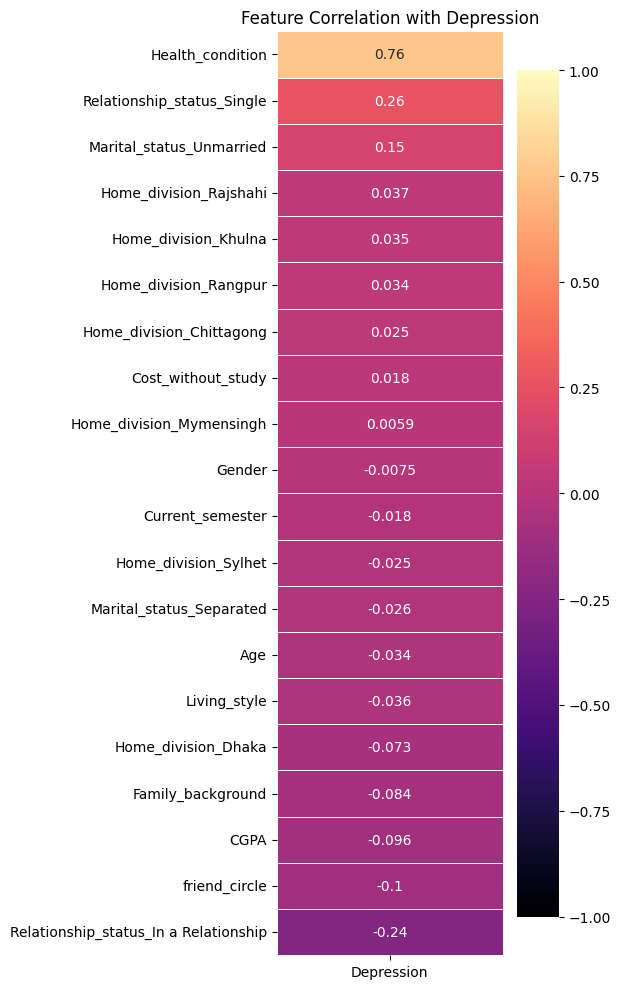

In [12]:
# Calculate correlations
corr = df.corr(numeric_only=True)["Depression"].drop("Depression")

# Sort descending
corr = corr.sort_values(ascending=False)

# Convert to DataFrame (single column)
corr_df = corr.to_frame()

# Plot
plt.figure(figsize=(6, 10))

sns.heatmap(
    corr_df,
    annot=True,
    cmap="magma",
    center=0,
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation with Depression")
plt.tight_layout()
plt.show()

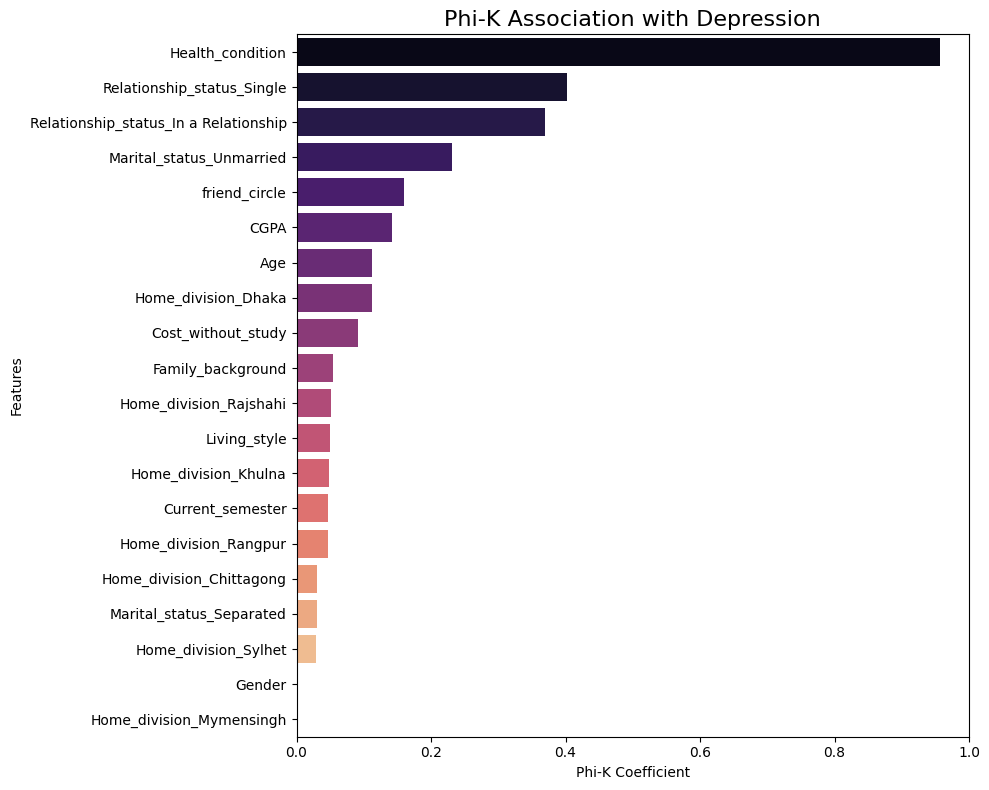

In [13]:
import phik
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Phi-K correlations
phik_corr = df.phik_matrix(
    interval_cols=df.select_dtypes(include="number").columns.tolist()
)

# Select Depression correlations
corr = phik_corr["Depression"].drop("Depression")
corr = corr.sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 8))

sns.barplot(
    x=corr.values,
    y=corr.index,
    hue=corr.index,
    palette="magma",
    legend=False
)

plt.title("Phi-K Association with Depression", fontsize=16)
plt.xlabel("Phi-K Coefficient")
plt.ylabel("Features")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

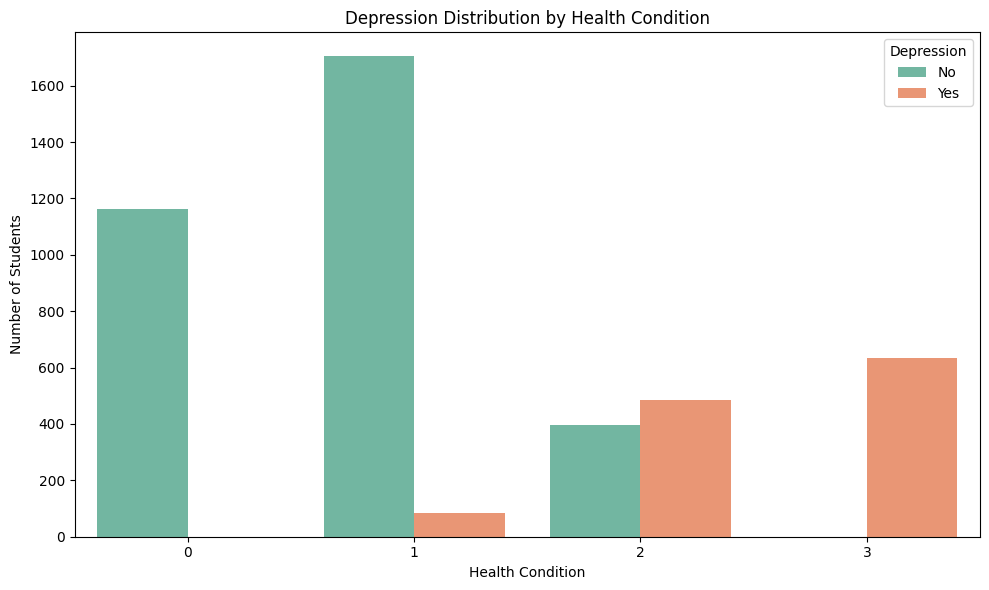

In [14]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Health_condition",
    hue="Depression",
    palette="Set2"
)

plt.title("Depression Distribution by Health Condition")
plt.xlabel("Health Condition")
plt.ylabel("Number of Students")
plt.legend(title="Depression", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

Makes sense. If your health is worse, you are more likely to be depressed.
These graphs are quick code from chatgpt, I wanted something more descriptive than basic heatmaps.

In [15]:
pd.set_option('display.float_format', '{:.2f}'.format)

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features (exclude target)
X = df.select_dtypes(include='number').drop(columns=['Depression'])

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(by='VIF', ascending=False))

                                  Feature  VIF
18  Relationship_status_In a Relationship 5.90
19             Relationship_status_Single 5.78
10                    Home_division_Dhaka 3.59
11                   Home_division_Khulna 2.25
13                 Home_division_Rajshahi 2.15
15                   Home_division_Sylhet 2.07
2                       Family_background 1.96
9                Home_division_Chittagong 1.95
14                  Home_division_Rangpur 1.87
8                      Cost_without_study 1.87
12               Home_division_Mymensingh 1.81
17               Marital_status_Unmarried 1.44
0                                  Gender 1.43
3                            Living_style 1.38
1                                     Age 1.26
16               Marital_status_Separated 1.20
4                        Current_semester 1.14
6                           friend_circle 1.07
7                        Health_condition 1.05
5                                    CGPA 1.03


## Step 1a

In [16]:
# Checking value_counts for the columns again.

for column in df.columns:
    values = df[column].value_counts()
    print(values)
    print()

Gender
1    2462
0    2002
Name: count, dtype: int64

Age
23    1161
21     726
22     614
25     523
20     513
24     430
26     187
18      86
27      83
19      65
28      62
17      14
Name: count, dtype: int64

Family_background
1    2642
0    1151
2     671
Name: count, dtype: int64

Living_style
0    2449
1    2015
Name: count, dtype: int64

Current_semester
5     752
4     553
2     543
8     511
3     511
6     500
7     404
9     286
11    119
10    114
1      88
0      42
12     40
13      1
Name: count, dtype: int64

CGPA
3.00    280
3.60    142
3.50    135
4.00    130
3.89    130
       ... 
2.29      1
2.43      1
2.47      1
2.48      1
2.42      1
Name: count, Length: 169, dtype: int64

friend_circle
1    3215
0    1249
Name: count, dtype: int64

Health_condition
1    1787
0    1162
2     881
3     634
Name: count, dtype: int64

Cost_without_study
10000    73
5000     71
9000     61
6000     59
8000     57
         ..
19033     1
1953      1
8532      1
18700     1
197

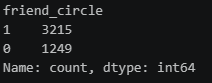

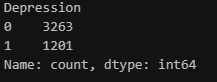

For example friend_circle has some inbalance. But so does depression. Lets choose depression, as the target variable might be interesting to experiment with.

## Step 1b

<Axes: xlabel='Depression', ylabel='Count'>

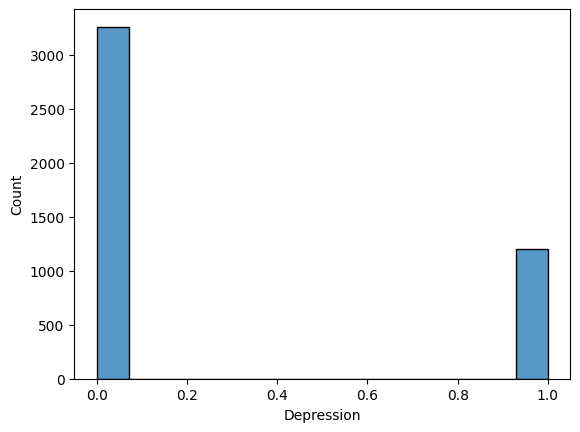

In [17]:
sns.histplot(df['Depression'])

## Step 1c.

In [18]:
df.shape

(4464, 21)

In [19]:
df.describe()

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
count,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,...,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00
mean,0.55,22.62,0.89,0.45,5.40,3.41,0.72,1.22,11242.98,0.27,...,0.34,0.12,0.08,0.11,0.08,0.10,0.03,0.81,0.33,0.63
std,0.50,2.02,0.63,0.50,2.58,0.39,0.45,0.99,6640.14,0.44,...,0.47,0.33,0.26,0.31,0.27,0.30,0.16,0.39,0.47,0.48
min,0.00,17.00,0.00,0.00,0.00,2.25,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,21.00,0.00,0.00,3.00,3.15,0.00,0.00,6100.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
50%,1.00,23.00,1.00,0.00,5.00,3.49,1.00,1.00,9500.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00
75%,1.00,24.00,1.00,1.00,7.00,3.70,1.00,2.00,15439.00,1.00,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00
max,1.00,28.00,2.00,1.00,13.00,4.00,1.00,3.00,32000.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


Lots of people are not depressed. Lets try undersampling that. It will drop a lot of data, but it's an experimentation after all.

## Step 1d.

In [20]:
from imblearn.under_sampling import RandomUnderSampler

# Split the dataset. If we don't do this, we WILL have a data leakage when training
# the model.
X = df.drop(columns="Depression", axis=1)
y = df["Depression"]

# We set a stable seed for the sampler.
sampler = RandomUnderSampler(random_state=321)

# We use the sampler, and output two variables (X, y respectively).
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Let's make an independent dataframe to be safe.
df_resampled = X_resampled.copy()

# And let's add the `Pop` column back into it.
df_resampled["Depression"] = y_resampled



In [21]:
df_resampled.describe()

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division_Chittagong,...,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single,Depression
count,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,...,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00,2402.00
mean,0.55,22.61,0.88,0.45,5.39,3.39,0.69,1.62,11354.35,0.10,...,0.13,0.08,0.11,0.09,0.10,0.03,0.84,0.26,0.69,0.50
std,0.50,2.07,0.62,0.50,2.59,0.39,0.46,1.05,6659.43,0.30,...,0.33,0.27,0.31,0.28,0.29,0.16,0.37,0.44,0.46,0.50
min,0.00,17.00,0.00,0.00,0.00,2.25,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,21.00,0.00,0.00,3.00,3.10,0.00,1.00,6200.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
50%,1.00,23.00,1.00,0.00,5.00,3.46,1.00,2.00,9872.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.50
75%,1.00,24.00,1.00,1.00,7.00,3.69,1.00,3.00,15518.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
max,1.00,28.00,2.00,1.00,12.00,4.00,1.00,3.00,32000.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


The distributions didn't change a lot. But we lost half of our data as expected.

## Step 1e & 1f

2402

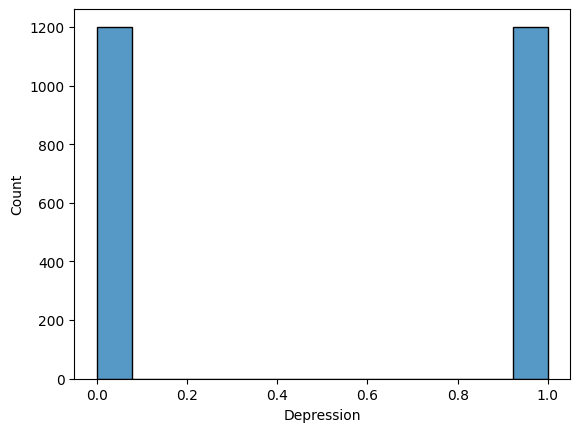

In [22]:
sns.histplot(df_resampled['Depression'])
len(df_resampled)

## Step 1e.

As already mentioned, I believe this experiment dropped too much data. The statistics did not change much, with a quick look, health status data changed a bit, but this was also expected as it correlates the most with depression. Maybe with this dataset, the best way to use this technique would be with helper variables with class imbalances, such as friend circle.

## Step 2a.

Lets now try to generate data with the friend circle column. It had some association with the target variable, according to phik matrix.

## Step 2b & 2c

<Axes: xlabel='friend_circle', ylabel='Count'>

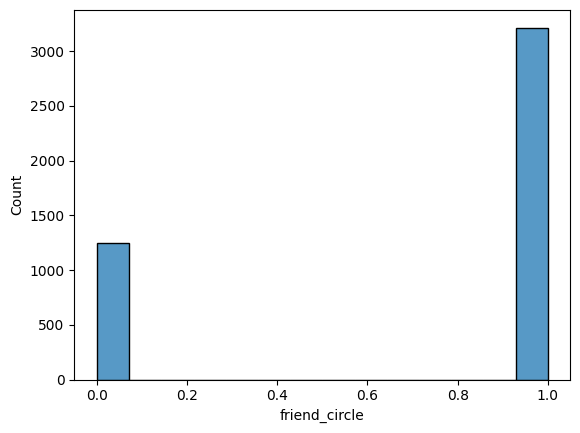

In [23]:
sns.histplot(df['friend_circle'])
# Most people have friend circles, when some people don't. 

In [24]:
df['friend_circle'].value_counts()

friend_circle
1    3215
0    1249
Name: count, dtype: int64

In [25]:
len(df)

4464

In [26]:
df['friend_circle'].value_counts()

friend_circle
1    3215
0    1249
Name: count, dtype: int64

## Step 2d.

In [27]:
from imblearn.over_sampling import SMOTE, ADASYN

target = "friend_circle"

X = df.drop(target, axis=1)
y = df[target]

# define sampling strategy
# NOTE! this is oversampling, you can go over the original limit
# because you are generating more data
strategy = {
    0: 2200,
    1: 3215,
    
}

# use SMOTE with default settings (often enough)
# model = SMOTE()
model = SMOTE(sampling_strategy=strategy, random_state=123)

# ADASYN is an alternative to SMOTE, but is often a bit trickier to
# use with custom sampling strategies, you can "auto" though
# model = ADASYN(sampling_strategy="auto", random_state=123)

X_resampled, y_resampled = model.fit_resample(X, y)

# reconstruct the dataframe
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled[target] = y_resampled

## Step 2e

<Axes: xlabel='friend_circle', ylabel='Count'>

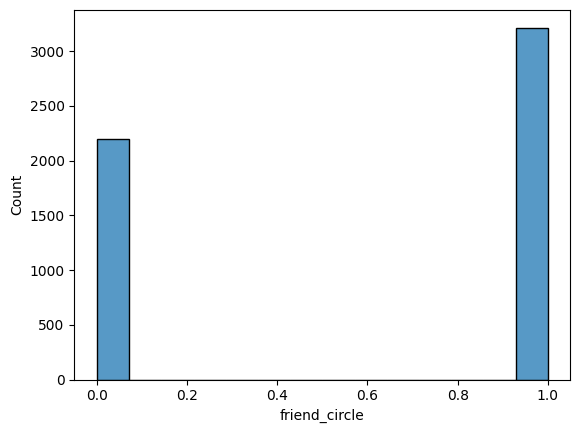

In [28]:
sns.histplot(df_resampled['friend_circle'])

# It looks more balanced now!

## Step 2f

In [29]:
len(df_resampled)

5415

## Step 2g

In [30]:
df.describe()

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
count,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,...,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00,4464.00
mean,0.55,22.62,0.89,0.45,5.40,3.41,0.72,1.22,11242.98,0.27,...,0.34,0.12,0.08,0.11,0.08,0.10,0.03,0.81,0.33,0.63
std,0.50,2.02,0.63,0.50,2.58,0.39,0.45,0.99,6640.14,0.44,...,0.47,0.33,0.26,0.31,0.27,0.30,0.16,0.39,0.47,0.48
min,0.00,17.00,0.00,0.00,0.00,2.25,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,21.00,0.00,0.00,3.00,3.15,0.00,0.00,6100.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
50%,1.00,23.00,1.00,0.00,5.00,3.49,1.00,1.00,9500.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00
75%,1.00,24.00,1.00,1.00,7.00,3.70,1.00,2.00,15439.00,1.00,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00
max,1.00,28.00,2.00,1.00,13.00,4.00,1.00,3.00,32000.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [31]:
df_resampled.describe()

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Home_division_Chittagong,...,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single,friend_circle
count,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,...,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00,5415.00
mean,0.54,22.55,0.88,0.43,5.32,3.41,1.17,11308.76,0.25,0.08,...,0.10,0.06,0.09,0.07,0.08,0.02,0.80,0.29,0.59,0.59
std,0.50,1.99,0.63,0.49,2.49,0.38,0.97,6695.22,0.43,0.27,...,0.31,0.24,0.29,0.25,0.28,0.15,0.40,0.45,0.49,0.49
min,0.00,17.00,0.00,0.00,0.00,2.25,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,21.00,0.00,0.00,3.00,3.15,0.00,6100.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
50%,1.00,23.00,1.00,0.00,5.00,3.47,1.00,9500.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00
75%,1.00,24.00,1.00,1.00,7.00,3.70,2.00,15622.50,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
max,1.00,28.00,2.00,1.00,13.00,4.00,3.00,32000.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [32]:
df['Depression'].value_counts()

Depression
0    3263
1    1201
Name: count, dtype: int64

In [33]:
df_resampled['Depression'].value_counts()

Depression
0    4082
1    1333
Name: count, dtype: int64

Surprisingly, the statistics did not change that much. I was thinking it would affect the target variable, 'Depression' way more than it did. My initial thoughts were that if people do not have friend circles, it would have some kind of a correlation to depression. But SMOTE gave us more data without depression, causing more imbalance with the target variable. This isn't great for the data and will not be optimal for ML.

## Step 3a.

I unfortunately do not have datasets, that clearly show the overlap. And spending two hours in kaggle is not my favourite passtime, so lets do it with the depression dataset.

## Step 3b

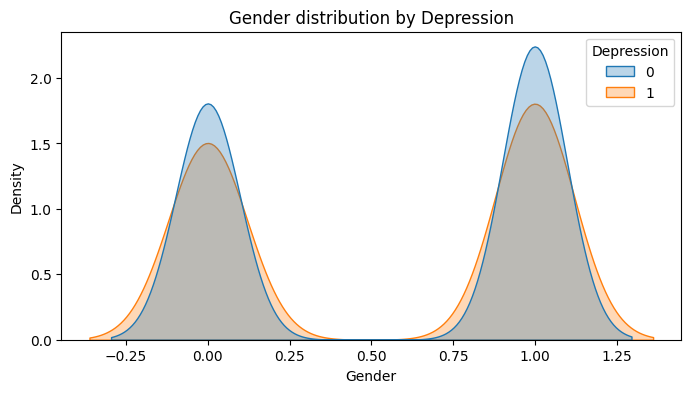

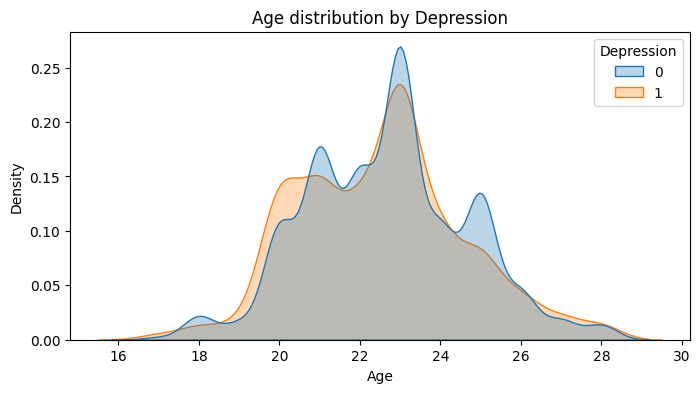

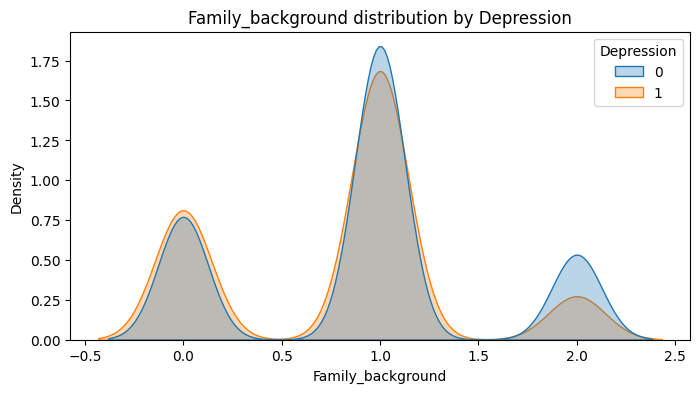

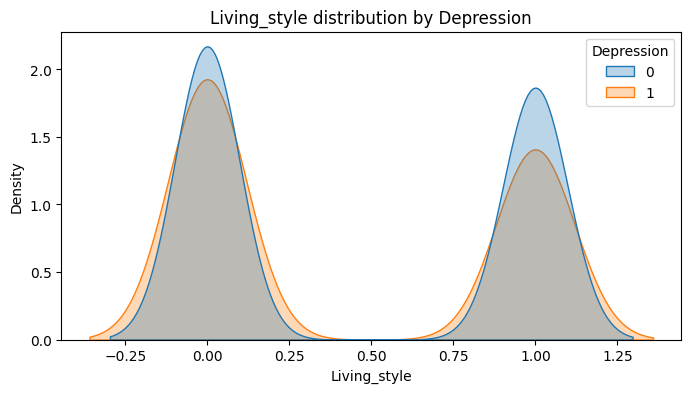

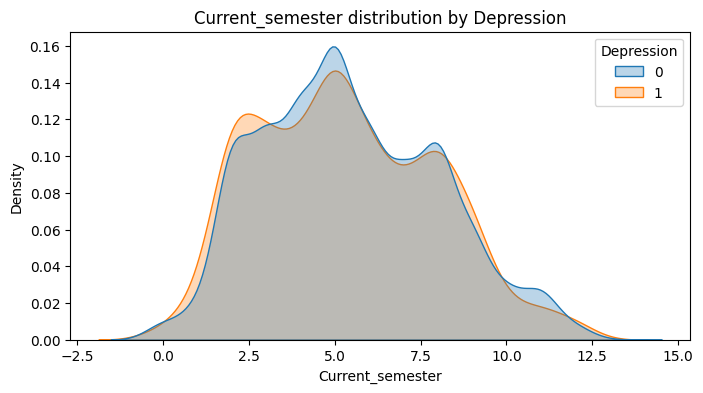

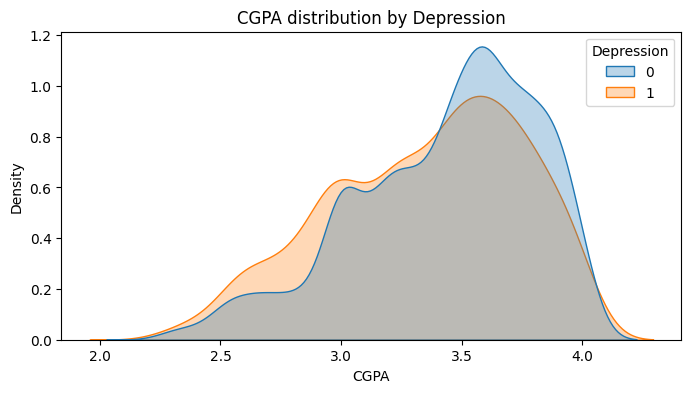

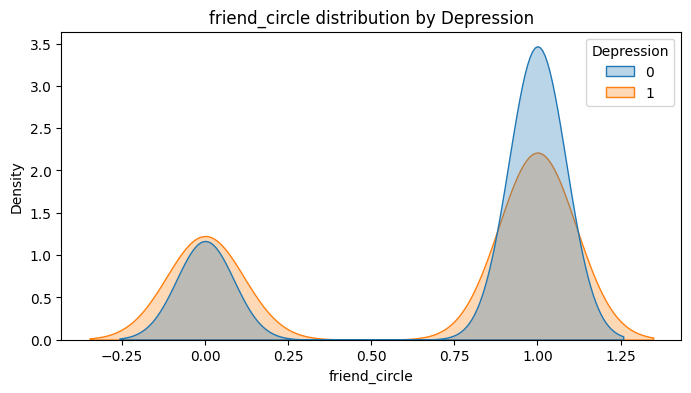

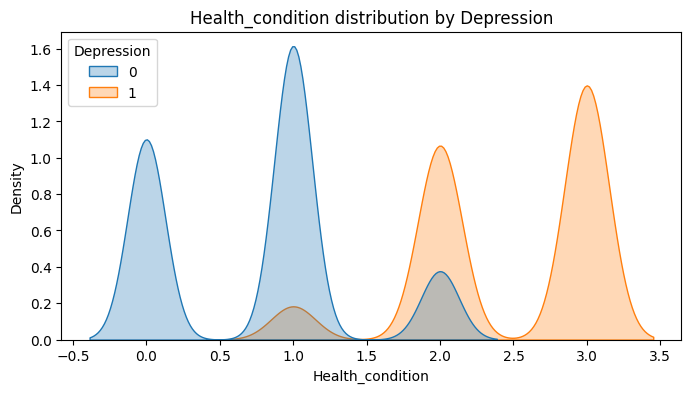

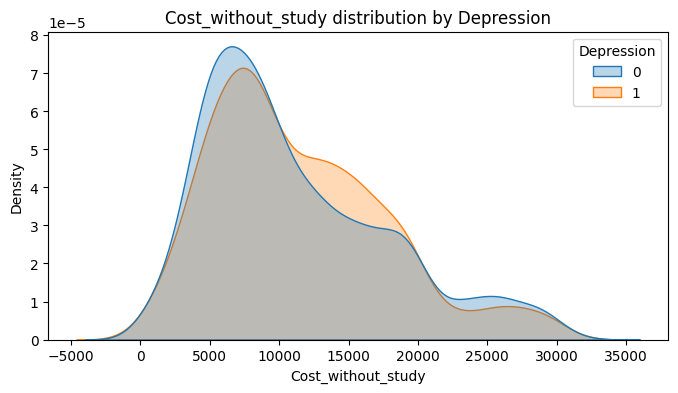

C:\Users\OMISTAJA\AppData\Local\Temp\ipykernel_27672\3642381195.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


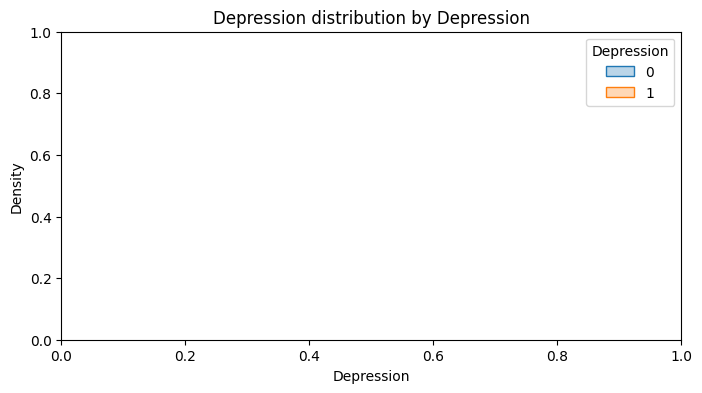

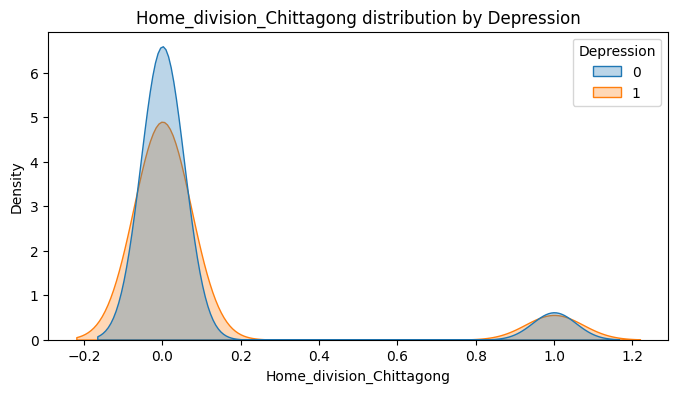

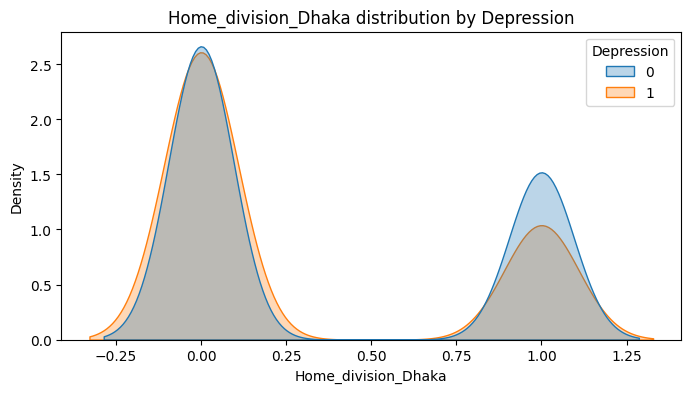

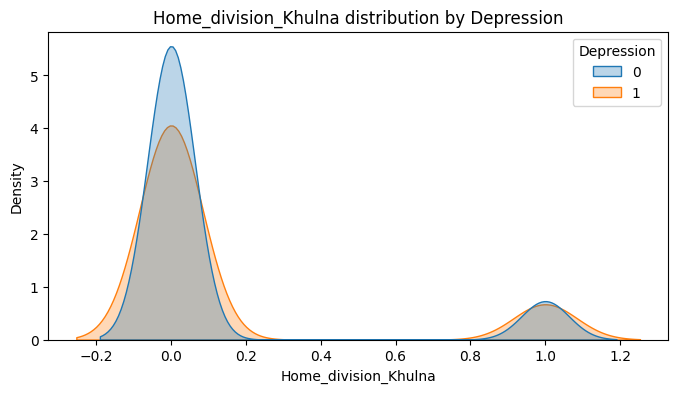

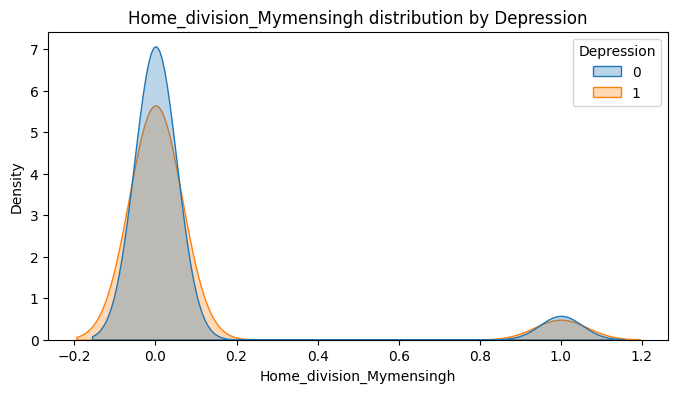

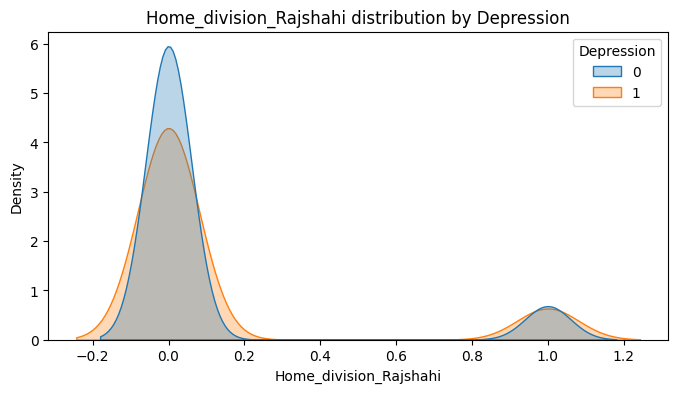

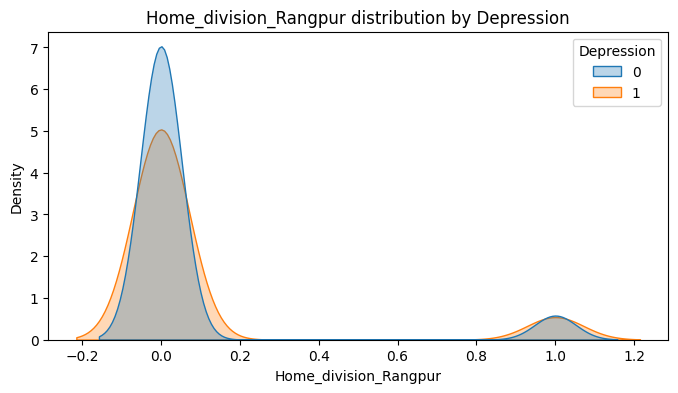

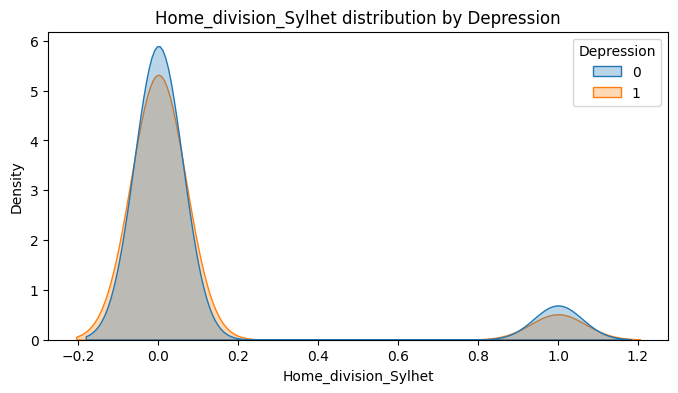

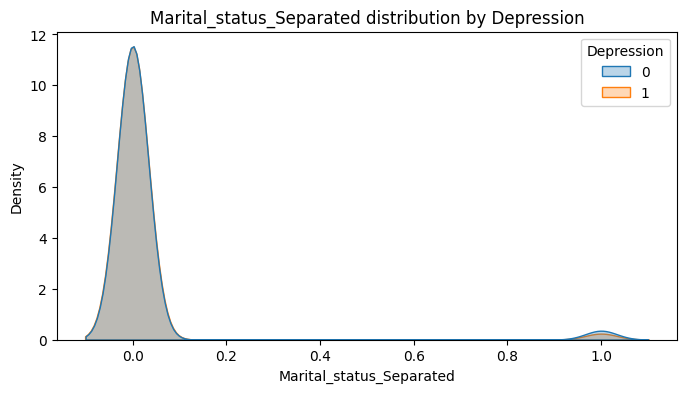

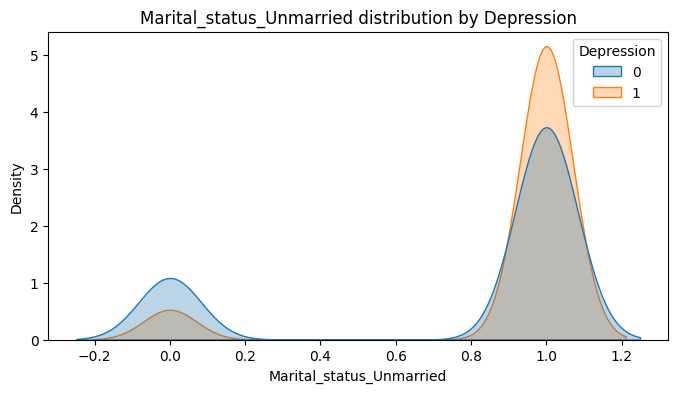

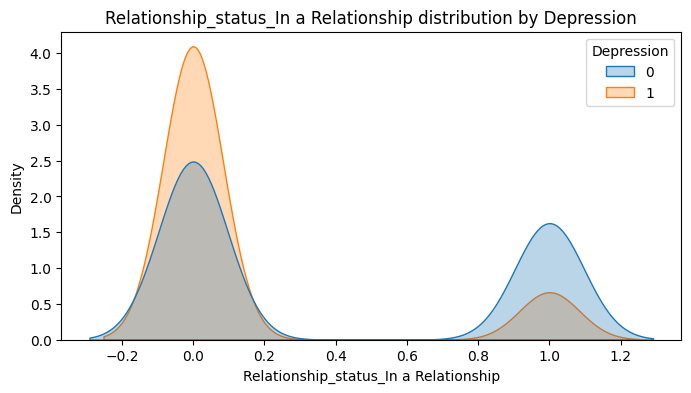

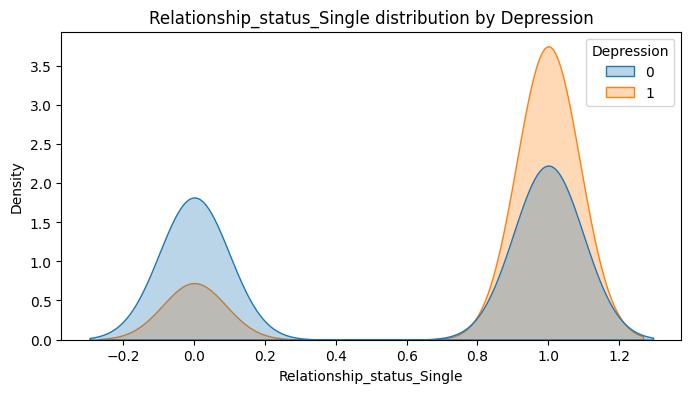

In [ ]:
# This dataset does barely show any overlap, these graphs are me exploring trying to find some. 

for col in df.columns:
    plt.figure(figsize=(8, 4))

    sns.kdeplot(
        data=df,
        x=col,
        hue="Depression",
        fill=True,
        common_norm=False,
        alpha=0.3
    )

    plt.title(f"{col} distribution by Depression")
    plt.show()

It definitely shows some great overlap, the curves are barely different with some of the columns.

## Step 3c

In [35]:
from imblearn.under_sampling import TomekLinks

df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="Depression", axis=1)
y = df["Depression"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["Depression"] = y_resampled
df_resampled

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division_Chittagong,...,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single,Depression
0,1,22,1,0,8,3.43,1,3,10113,1,...,0,0,0,0,0,0,1,0,1,1
1,0,19,1,0,2,3.70,1,2,13815,1,...,0,0,0,0,0,0,1,0,1,1
2,0,23,1,1,8,3.28,0,2,15450,0,...,0,0,0,0,0,0,1,0,1,1
3,1,21,1,1,1,4.00,0,2,16693,0,...,0,0,0,0,0,0,1,0,1,1
4,1,24,1,0,9,3.80,1,1,17244,1,...,0,0,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4123,1,26,1,1,11,2.97,0,3,12619,0,...,1,0,0,0,0,1,0,1,0,1
4124,0,28,0,1,8,2.60,0,1,2806,0,...,0,0,1,0,0,0,1,0,1,1
4125,1,23,1,0,10,2.80,0,0,14066,0,...,0,0,1,0,0,0,0,1,0,0
4126,1,23,1,1,5,3.00,1,1,14338,0,...,0,0,0,0,0,0,0,0,0,0


In [36]:
print(df.shape)
print(df_resampled.shape)

(4464, 21)
(4128, 21)


## Step 3d & 3e

It looks like TomekLinks dropped 870 rows in total. 

Scroll down for a short analysis.

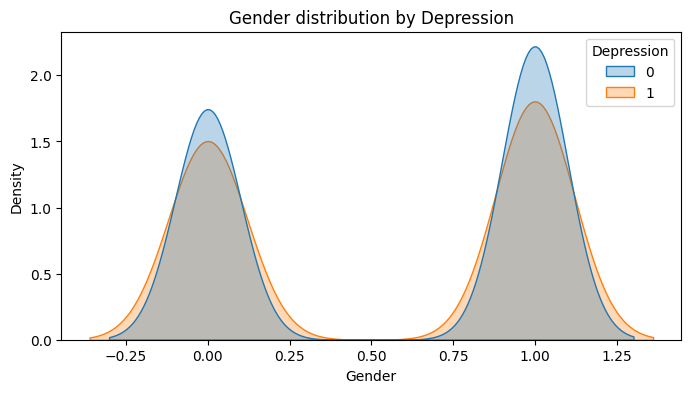

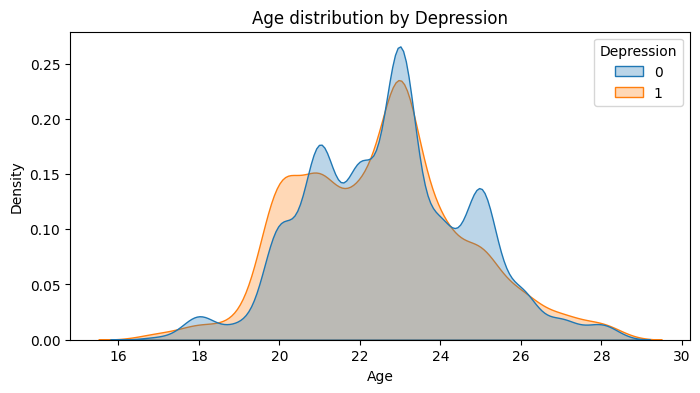

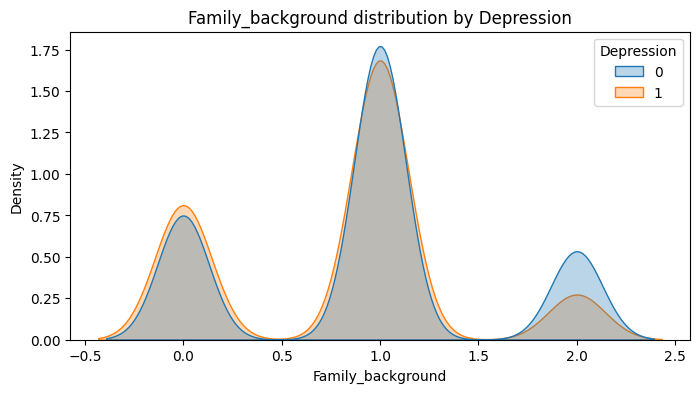

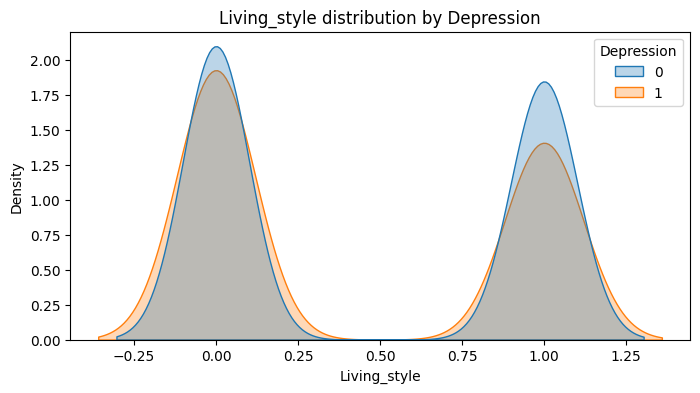

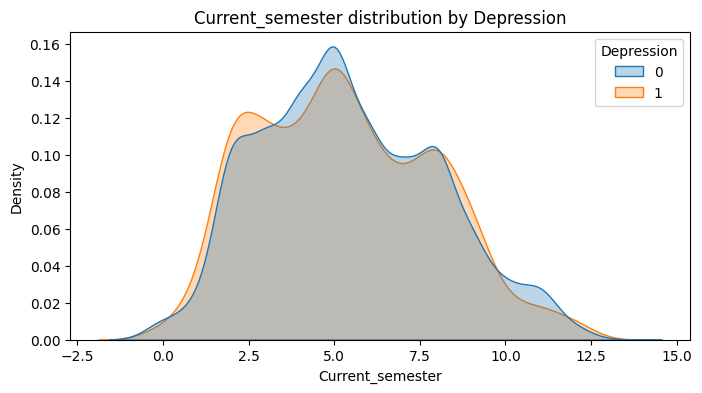

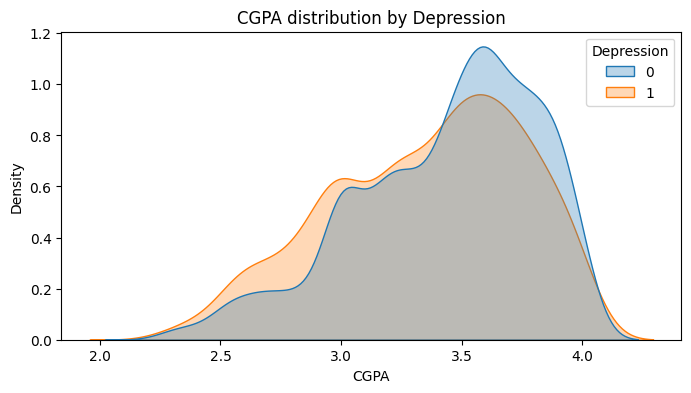

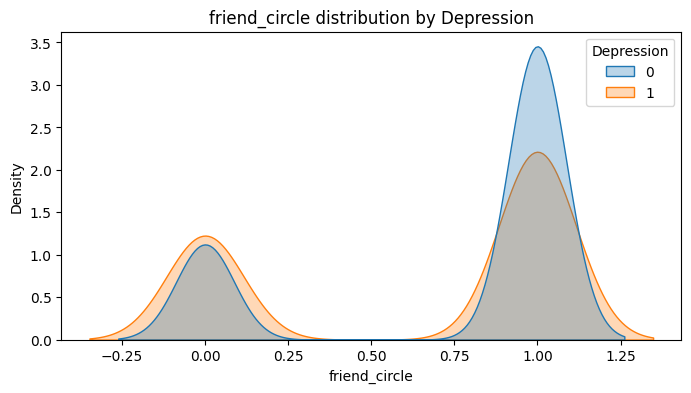

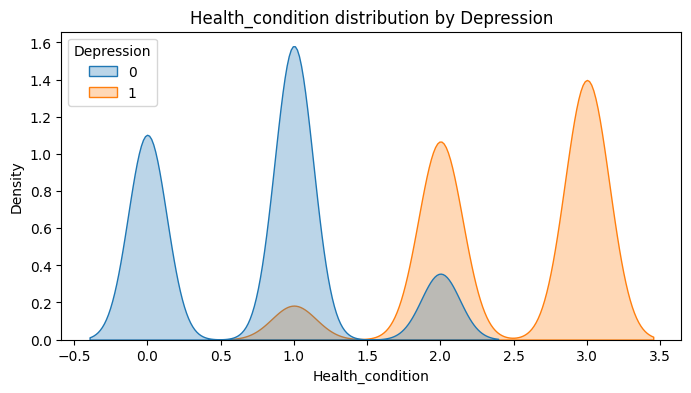

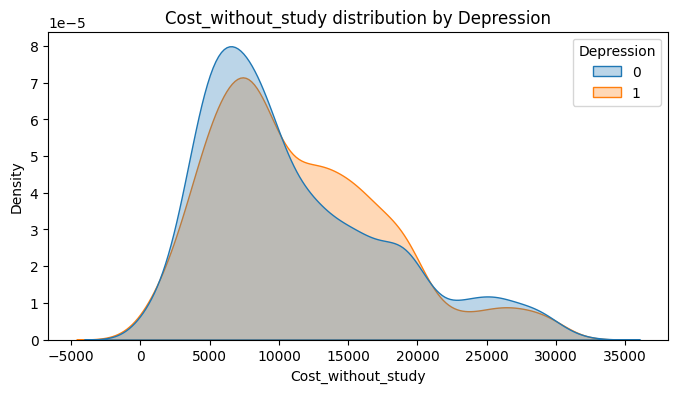

C:\Users\OMISTAJA\AppData\Local\Temp\ipykernel_27672\1235104303.py:6: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


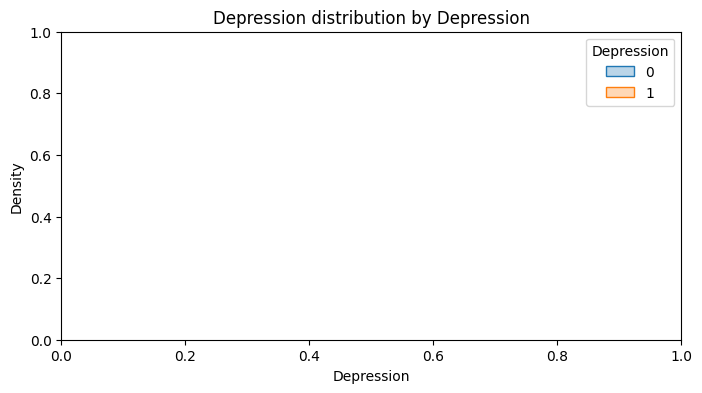

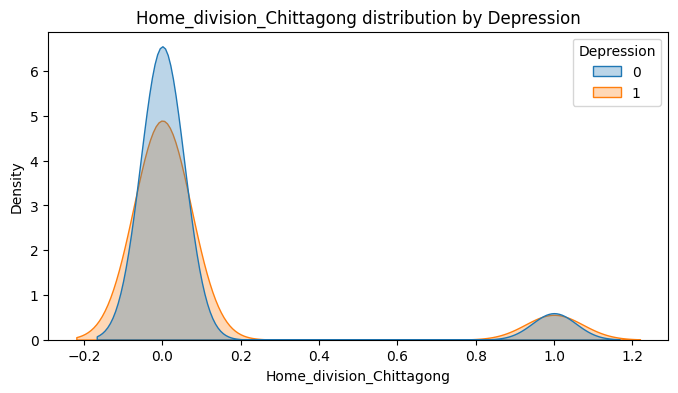

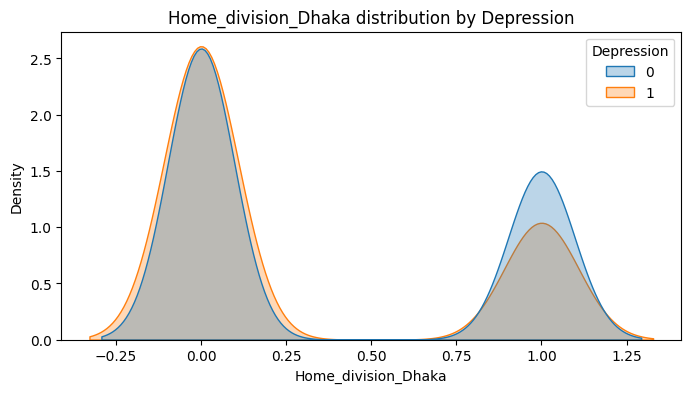

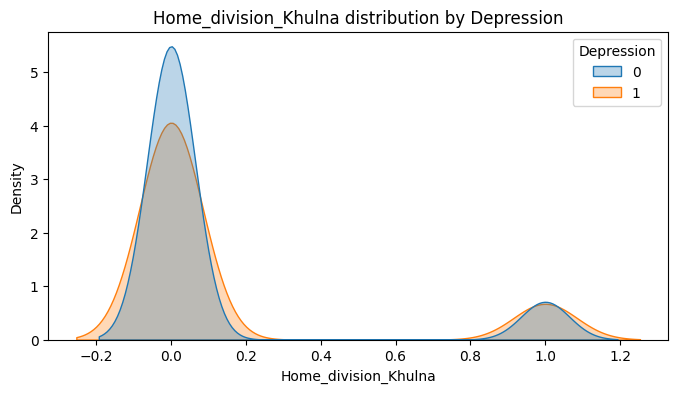

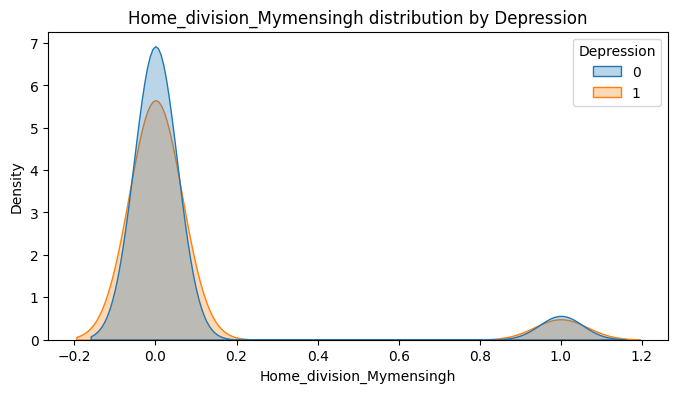

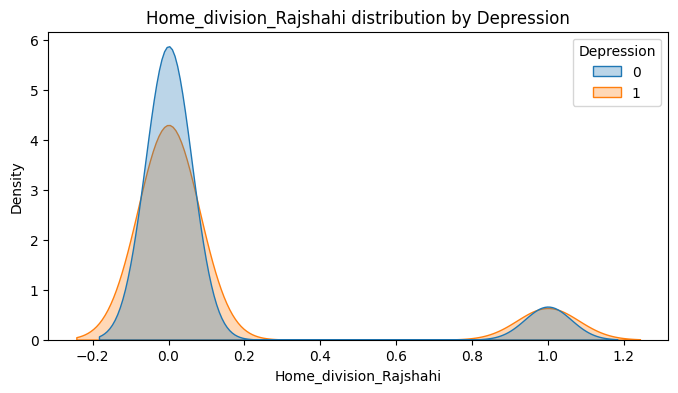

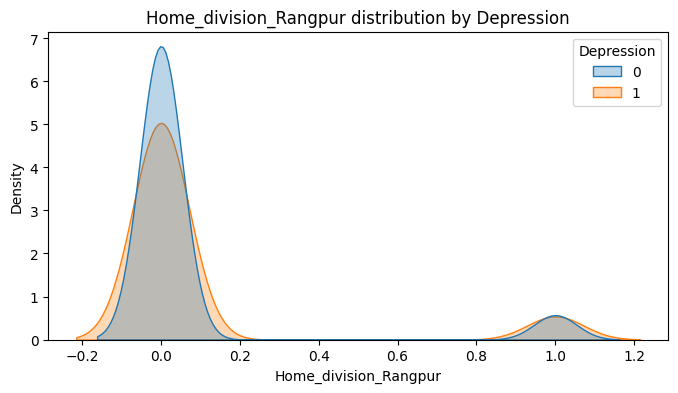

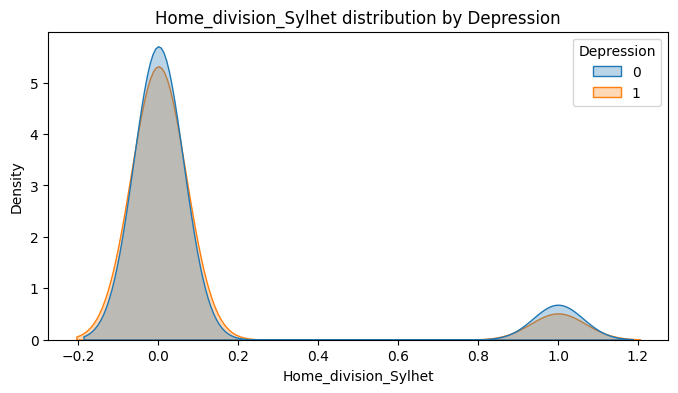

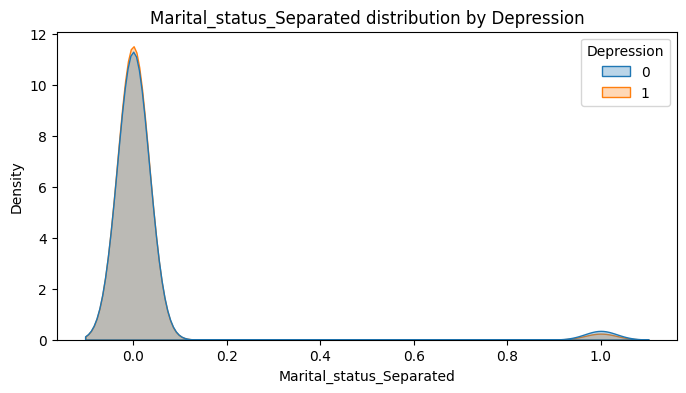

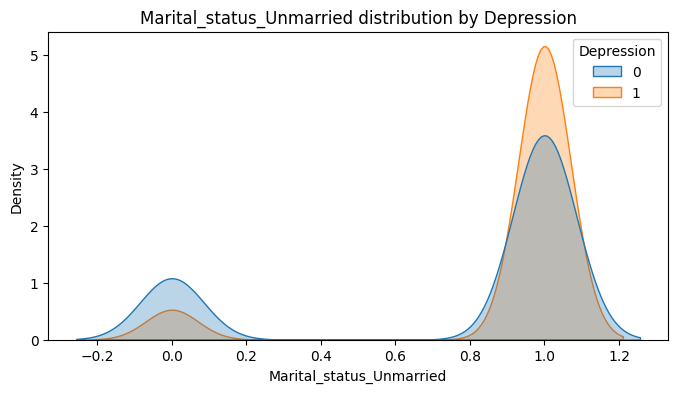

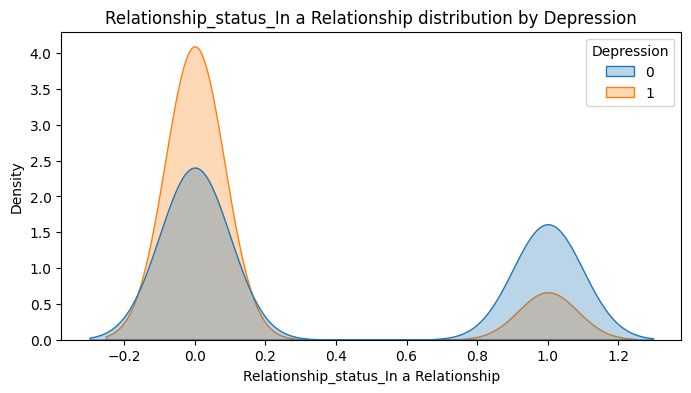

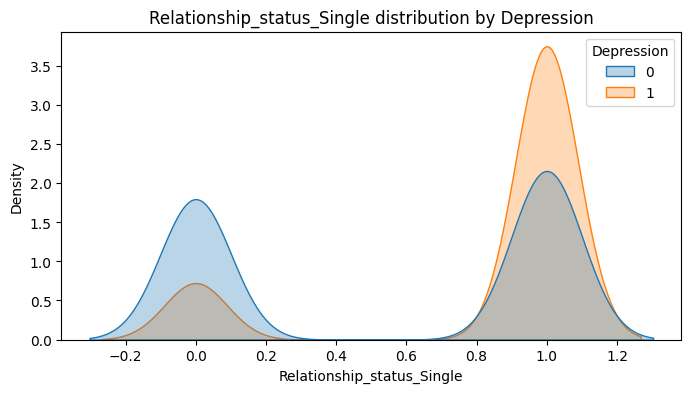

In [37]:
# Now with df_resampled

for col in df.columns:
    plt.figure(figsize=(8, 4))

    sns.kdeplot(
        data=df_resampled,
        x=col,
        hue="Depression",
        fill=True,
        common_norm=False,
        alpha=0.3
    )

    plt.title(f"{col} distribution by Depression")
    plt.show()

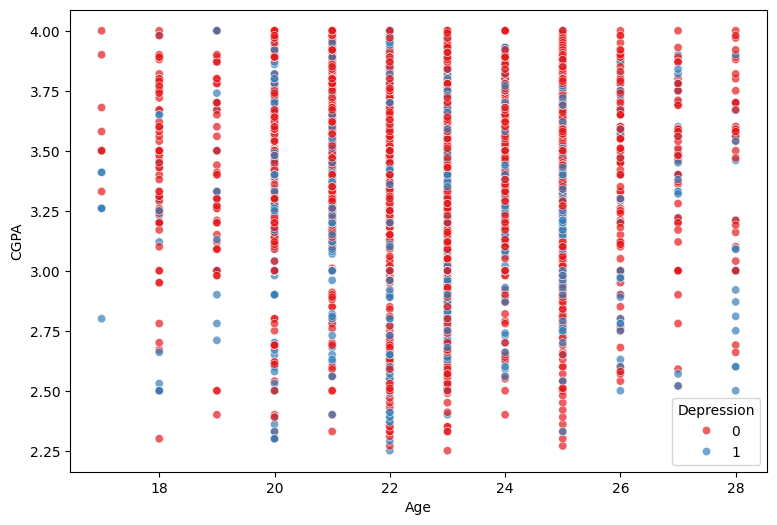

In [38]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="CGPA",
    hue="Depression",
    alpha=0.7,
    palette="Set1"
)

plt.show()

In [39]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Living_style',
       'Current_semester', 'CGPA', 'friend_circle', 'Health_condition',
       'Cost_without_study', 'Depression', 'Home_division_Chittagong',
       'Home_division_Dhaka', 'Home_division_Khulna',
       'Home_division_Mymensingh', 'Home_division_Rajshahi',
       'Home_division_Rangpur', 'Home_division_Sylhet',
       'Marital_status_Separated', 'Marital_status_Unmarried',
       'Relationship_status_In a Relationship', 'Relationship_status_Single'],
      dtype='object')

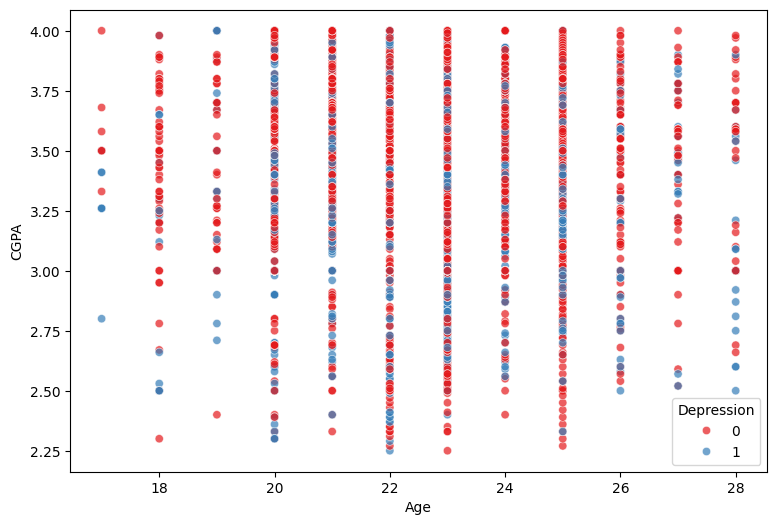

In [40]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_resampled,
    x="Age",
    y="CGPA",
    hue="Depression",
    alpha=0.7,
    palette="Set1"
)

plt.show()

The scatterplots do not seem to show really any differences between the two dataframes. 

The biggest issue I had was that I did not have a proper dataset to clearly find overlaps, and I found the topic also quite difficult. It clearly did drop something. I do understand the concept though, that using Tomek would be the best if some classes are all over the place. 

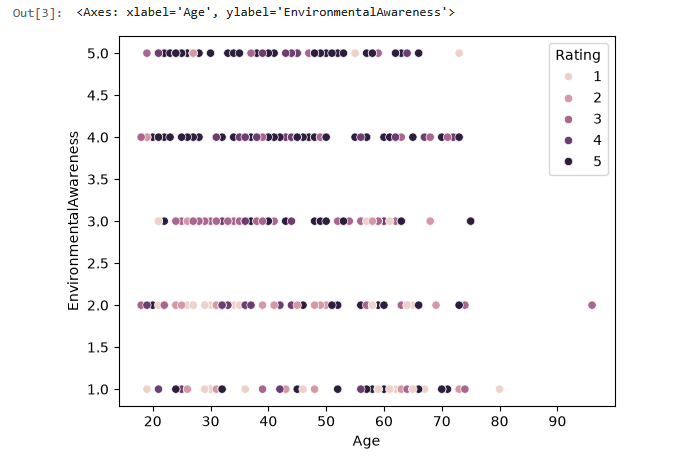

For example, in this picture which is found from the teacher's examples. The overlap is clear here and easily understood. The rating is all over the place with these two different features. I struggled to find anything as clear as this. It could be the nature of the dataset as it is full of categorical features, or the gap in the knowledge of the author.

In [41]:
# Code to see what was removed when comparing to target

comparison = pd.DataFrame({
    "Original": df["Depression"].value_counts(),
    "After TomekLinks": df_resampled["Depression"].value_counts()
})

print(comparison)

            Original  After TomekLinks
Depression                            
0               3263              2927
1               1201              1201
